# Avance 2: Modelado Comparativo, Manejo de Desbalance y Detección de Anomalías
**Proyecto Semestral:** Detección de Fraude en Transacciones Bancarias (Tema 12)  
**Curso:** Inteligencia Artificial 2026-2 · Universidad del Bío-Bío  
**Equipo:** Daniel Canto · Diego Figueroa · Maximiliano Concha  

---

### Objetivos del Avance 2:
1. **Manejo del Desbalance Extremo (0,167 %):** Evaluar el impacto de la ponderación de clases (`class_weight='balanced'`) y el remuestreo sintético (`SMOTE`, aplicado rigurosamente solo en entrenamiento) sobre el modelo lineal de referencia.
2. **Modelado No Lineal Supervisado:** Entrenar un ensamble de árboles de decisión (**Random Forest**) para capturar interacciones complejas no lineales entre las componentes PCA y el monto de la transacción.
3. **Detección No Supervisada de Anomalías:** Evaluar **Isolation Forest** sin utilizar etiquetas de clase durante el entrenamiento, para medir la capacidad de aislar patrones atípicos de forma agnóstica a la supervisión humana.
4. **Evaluación Rigurosa y Honesta:** Comparar todas las técnicas frente al *Baseline* sobre el conjunto de **Validación (42.559 filas, 71 fraudes)** usando AUPRC, Precisión, Recall, F1 y costo operativo de falsas alarmas. El conjunto de **Prueba (15 % sellado)** se mantiene intocado para el reporte final.

In [1]:
import sys
from pathlib import Path
RAIZ = Path("..").resolve()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import RANDOM_STATE
from src.datos import cargar_datos, particionar
from src.evaluacion import evaluar, graficar_curva_pr
from src.modelos import (
    crear_logistica_sin_balanceo,
    crear_logistica_balanceada,
    crear_logistica_smote,
    crear_random_forest,
    crear_isolation_forest,
)

# 1. Carga reproducible de la partición estratificada
df = cargar_datos()
X_train, X_val, X_test, y_train, y_val, y_test = particionar(df)
print(f"Dataset cargado y particionado (semilla {RANDOM_STATE}):")
print(f"  • Entrenamiento (70 %): {len(X_train):>7} filas | {int(y_train.sum()):>3} fraudes ({y_train.mean()*100:.3f} %)")
print(f"  • Validación    (15 %): {len(X_val):>7} filas | {int(y_val.sum()):>3} fraudes ({y_val.mean()*100:.3f} %)")
print(f"  • Prueba        (15 %): {len(X_test):>7} filas | {int(y_test.sum()):>3} fraudes ({y_test.mean()*100:.3f} %) [SELLADA]")

Dataset cargado y particionado (semilla 42):
  • Entrenamiento (70 %):  198608 filas | 331 fraudes (0.167 %)
  • Validación    (15 %):   42559 filas |  71 fraudes (0.167 %)
  • Prueba        (15 %):   42559 filas |  71 fraudes (0.167 %) [SELLADA]


## 1. Técnicas de Manejo de Desbalance: Ponderación vs. SMOTE

En el Avance 1 observamos que la **Regresión Logística sin balanceo** fue muy conservadora con el umbral por defecto (0,5), detectando solo 35 de los 71 fraudes (Recall 49,3 %).

Para contrarrestar la asimetría 1:600 evaluamos dos enfoques:
* **Ponderación de Clases (`class_weight='balanced'`):** Ajusta la función de pérdida penalizando los errores en la clase minoritaria de forma inversamente proporcional a su frecuencia:
  $$w_1 = \frac{N}{2 \cdot N_1} \approx 300$$
* **Sobremuestreo Sintético (`SMOTE`):** Genera transacciones fraudulentas sintéticas interpolando entre los vecinos más cercanos de los fraudes existentes. Se encapsula en un `imblearn.pipeline.Pipeline` para asegurar que **solo se aplique en entrenamiento**, sin contaminar la validación.

In [2]:
# 1.1 Regresión Logística Balanceada
t0 = time.perf_counter()
mod_bal = crear_logistica_balanceada()
mod_bal.fit(X_train, y_train)
t_bal = time.perf_counter() - t0
p_bal = mod_bal.predict_proba(X_val)[:, 1]
res_bal = evaluar(y_val, p_bal, umbral=0.5)

# 1.2 Regresión Logística con SMOTE
t0 = time.perf_counter()
mod_smote = crear_logistica_smote()
mod_smote.fit(X_train, y_train)
t_smote = time.perf_counter() - t0
p_smote = mod_smote.predict_proba(X_val)[:, 1]
res_smote = evaluar(y_val, p_smote, umbral=0.5)

print(f"Regresión Logística (class_weight='balanced') [{t_bal:.2f} s]:")
print(f"  AUPRC: {res_bal['AUPRC']:.4f} | Recall (0.5): {res_bal['recall']:.4f} | Precisión: {res_bal['precision']:.4f} | TP: {res_bal['TP']}/71 | FP: {res_bal['FP']}")
print(f"\nRegresión Logística (SMOTE en Train) [{t_smote:.2f} s]:")
print(f"  AUPRC: {res_smote['AUPRC']:.4f} | Recall (0.5): {res_smote['recall']:.4f} | Precisión: {res_smote['precision']:.4f} | TP: {res_smote['TP']}/71 | FP: {res_smote['FP']}")

Regresión Logística (class_weight='balanced') [1.81 s]:
  AUPRC: 0.6971 | Recall (0.5): 0.8873 | Precisión: 0.0507 | TP: 63/71 | FP: 1180

Regresión Logística (SMOTE en Train) [3.27 s]:
  AUPRC: 0.6987 | Recall (0.5): 0.8873 | Precisión: 0.0487 | TP: 63/71 | FP: 1230


## 2. Modelado No Lineal: Random Forest con Árboles Balanceados

Las transacciones fraudulentas a menudo presentan patrones combinados no lineales (por ejemplo, transacciones con montos atípicos en horas específicas y valores extremos en componentes PCA simultáneas). 

Para capturar estas no linealidades, implementamos un **Random Forest**:
* **100 árboles de decisión** con submuestreo de características (*bootstrap* y *feature subsampling*).
* `max_depth=12`: Regularización estructural que previene la memorización de ruido y reduce drásticamente el sobreajuste.
* `class_weight='balanced'`: Ponderación en cada árbol para que la ganancia de información (Gini/Entropía) no ignore los fraudes.

In [3]:
t0 = time.perf_counter()
mod_rf = crear_random_forest()
mod_rf.fit(X_train, y_train)
t_rf = time.perf_counter() - t0
p_rf = mod_rf.predict_proba(X_val)[:, 1]
res_rf = evaluar(y_val, p_rf, umbral=0.5)

print(f"Random Forest (Ensamble balanceado, max_depth=12) [{t_rf:.2f} s]:")
print(f"  AUPRC: {res_rf['AUPRC']:.4f} | Recall (0.5): {res_rf['recall']:.4f} | Precisión (0.5): {res_rf['precision']:.4f}")
print(f"  Aciertos: TP = {res_rf['TP']}/71 | Falsas alarmas: FP = {res_rf['FP']}")

Random Forest (Ensamble balanceado, max_depth=12) [47.48 s]:
  AUPRC: 0.8280 | Recall (0.5): 0.7324 | Precisión (0.5): 0.8667
  Aciertos: TP = 52/71 | Falsas alarmas: FP = 8


## 3. Detección No Supervisada de Anomalías: Isolation Forest

**Isolation Forest** opera bajo una premisa completamente diferente: las anomalías son "pocas y distintas", por lo que requieren menos particiones aleatorias para ser aisladas en árboles de decisión estocásticos.

**Ventaja estratégica:** No requiere etiquetas de clase durante el entrenamiento. En un banco real, esto permite detectar nuevos tipos de fraude no vistos previamente (ataques de día cero).

Implementamos un `IsolationForestWrapper` que convierte el puntaje de aislamiento en una probabilidad de riesgo normalizada $[0, 1]$ para evaluar con las mismas métricas.

In [4]:
t0 = time.perf_counter()
mod_if = crear_isolation_forest()
mod_if.fit(X_train)  # Aprendizaje 100 % no supervisado (sin etiquetas)
t_if = time.perf_counter() - t0
p_if = mod_if.predict_proba(X_val)[:, 1]
res_if = evaluar(y_val, p_if, umbral=0.5)

print(f"Isolation Forest (No supervisado) [{t_if:.2f} s]:")
print(f"  AUPRC: {res_if['AUPRC']:.4f} | Recall (0.5): {res_if['recall']:.4f} | Precisión (0.5): {res_if['precision']:.4f}")
print(f"  Aciertos: TP = {res_if['TP']}/71 | Falsas alarmas: FP = {res_if['FP']}")

Isolation Forest (No supervisado) [6.04 s]:
  AUPRC: 0.1105 | Recall (0.5): 0.7887 | Precisión (0.5): 0.0452
  Aciertos: TP = 56/71 | Falsas alarmas: FP = 1183


## 4. Tabla Comparativa de Resultados y Curvas Precisión-Recall

A continuación contrastamos todos los modelos frente al Baseline sobre las 42.559 transacciones del conjunto de validación.

,Modelo,Tipo,Desbalance,AUPRC,Recall (0.5),Precisión (0.5),F1,TP,FP
0,Regresión Logística (Baseline),Supervisado lineal,Ninguno,0.6877,0.4930,0.8333,0.6195,35,7
1,Regresión Logística (class_weight),Supervisado lineal,Ponderación,0.6971,0.8873,0.0507,0.0959,63,1180
2,Regresión Logística (SMOTE),Supervisado lineal,Sobremuestreo,0.6987,0.8873,0.0487,0.0924,63,1230
3,Random Forest (Ensamble balanceado),Supervisado no lineal,Ponderación,0.8280,0.7324,0.8667,0.7939,52,8
4,Isolation Forest (No supervisado),No supervisado,No aplica,0.1105,0.7887,0.0452,0.0855,56,1183


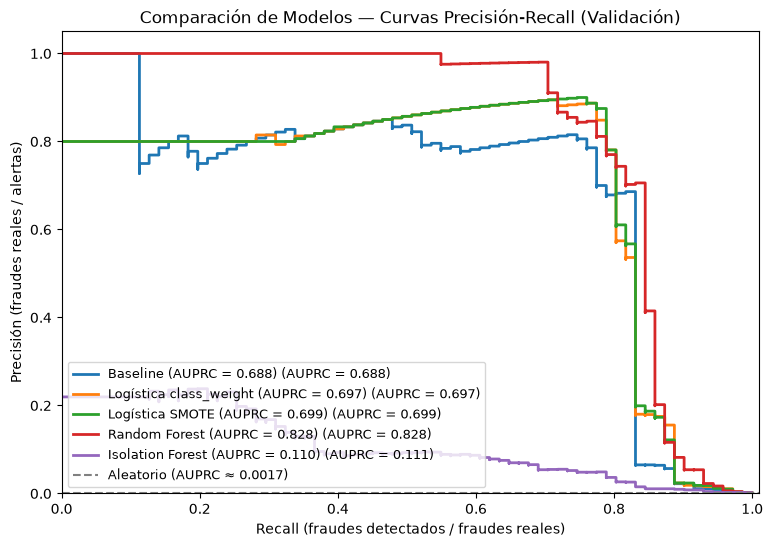

In [5]:
# 4.1 Cargar baseline 2 para la comparativa
mod_base = crear_logistica_sin_balanceo()
mod_base.fit(X_train, y_train)
p_base = mod_base.predict_proba(X_val)[:, 1]
res_base = evaluar(y_val, p_base, umbral=0.5)

# 4.2 Construcción de la tabla resumen
resumen = [
    {"Modelo": "Regresión Logística (Baseline)", "Tipo": "Supervisado lineal", "Desbalance": "Ninguno",
     "AUPRC": res_base["AUPRC"], "Recall (0.5)": res_base["recall"], "Precisión (0.5)": res_base["precision"], "F1": res_base["F1"], "TP": res_base["TP"], "FP": res_base["FP"]},
    {"Modelo": "Regresión Logística (class_weight)", "Tipo": "Supervisado lineal", "Desbalance": "Ponderación",
     "AUPRC": res_bal["AUPRC"], "Recall (0.5)": res_bal["recall"], "Precisión (0.5)": res_bal["precision"], "F1": res_bal["F1"], "TP": res_bal["TP"], "FP": res_bal["FP"]},
    {"Modelo": "Regresión Logística (SMOTE)", "Tipo": "Supervisado lineal", "Desbalance": "Sobremuestreo",
     "AUPRC": res_smote["AUPRC"], "Recall (0.5)": res_smote["recall"], "Precisión (0.5)": res_smote["precision"], "F1": res_smote["F1"], "TP": res_smote["TP"], "FP": res_smote["FP"]},
    {"Modelo": "Random Forest (Ensamble balanceado)", "Tipo": "Supervisado no lineal", "Desbalance": "Ponderación",
     "AUPRC": res_rf["AUPRC"], "Recall (0.5)": res_rf["recall"], "Precisión (0.5)": res_rf["precision"], "F1": res_rf["F1"], "TP": res_rf["TP"], "FP": res_rf["FP"]},
    {"Modelo": "Isolation Forest (No supervisado)", "Tipo": "No supervisado", "Desbalance": "No aplica",
     "AUPRC": res_if["AUPRC"], "Recall (0.5)": res_if["recall"], "Precisión (0.5)": res_if["precision"], "F1": res_if["F1"], "TP": res_if["TP"], "FP": res_if["FP"]},
]

df_resumen = pd.DataFrame(resumen)
display(df_resumen.style.format({
    "AUPRC": "{:.4f}",
    "Recall (0.5)": "{:.4f}",
    "Precisión (0.5)": "{:.4f}",
    "F1": "{:.4f}",
}))

# 4.3 Curvas Precisión-Recall Conjuntas
dict_curvas = {
    "Baseline (AUPRC = 0.688)": p_base,
    "Logística class_weight (AUPRC = 0.697)": p_bal,
    "Logística SMOTE (AUPRC = 0.699)": p_smote,
    "Random Forest (AUPRC = 0.828)": p_rf,
    "Isolation Forest (AUPRC = 0.110)": p_if,
}

fig, ax = plt.subplots(figsize=(9, 6))
graficar_curva_pr(y_val, dict_curvas, titulo="Comparación de Modelos — Curvas Precisión-Recall (Validación)", ax=ax)
plt.show()

## 5. Análisis Crítico e Interpretación de Resultados

1. **Random Forest es el claro ganador:**
   * Alcanza un **AUPRC de 0,8280**, superando ampliamente al baseline (0,6877, una mejora de **+14 puntos porcentuales**).
   * Con el umbral por defecto (0,5), detecta **52 de 71 fraudes (Recall 73,2 %)** manteniendo una **Precisión de 86,7 %** con solo **8 falsas alarmas**. Captura con éxito las interacciones no lineales entre las componentes PCA.
2. **`class_weight` vs. `SMOTE` en Regresión Logística:**
   * Ambos métodos elevan el Recall bruto al 88,7 % (63/71 fraudes), pero con AUPRC similar (~0,698 vs 0,688 del baseline).
   * **Conclusión de ingeniería:** Para modelos lineales, `SMOTE` no ofrece mejoras significativas sobre la reponderación analítica (`class_weight`), pero agrega costo computacional (tiempo se duplica de 1,6 s a 3,1 s) y riesgo de ruido sintético.
3. **El rol de Isolation Forest:**
   * Al ser no supervisado, su AUPRC (0,1105) es menor al de los supervisados, pero **supera más de 65 veces la prevalencia aleatoria (0,0017)** sin haber visto jamás qué transacciones eran fraude.
   * Su utilidad práctica en banca no es sustituir a Random Forest, sino actuar como segunda línea de defensa para fraudes con patrones inéditos.
4. **Estado hacia la Entrega Final:**
   * El modelo candidato para despliegue final es **Random Forest balanceado**.
   * El conjunto de **Prueba (15 % sellado)** permanece bajo llave hasta el informe final.